In [40]:
## importing the required libraries and dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df=pd.read_excel('marketing_campaigns_analysis.xlsx')

In [8]:
df['channel'].unique()

<ArrowStringArray>
['paid_search', 'paid_social', 'display', 'video', 'affiliate']
Length: 5, dtype: str

In [14]:
campaigns = df['campaign_id'].unique()

In [21]:
##campaign start and end dates

campaign_date=df.groupby('campaign_id')['spend_date'].agg(start_date='min',end_date='max')
print(campaign_date)

             start_date    end_date
campaign_id                        
CMP0001      2023-06-17  2023-08-17
CMP0002      2023-09-27  2023-11-18
CMP0003      2024-09-27  2024-12-26
CMP0004      2024-10-15  2025-02-16
CMP0005      2024-10-20  2024-12-29
...                 ...         ...
CMP0116      2023-05-19  2023-09-04
CMP0117      2023-08-12  2023-12-06
CMP0118      2023-10-16  2024-03-08
CMP0119      2025-07-02  2025-09-04
CMP0120      2023-08-14  2023-10-09

[120 rows x 2 columns]


In [20]:
# Check funnel consistency

print("Clicks greater than impressions:",
      (df["clicks"] > df["impressions"]).sum())
print("Leads greater than clicks:",
      (df["leads"] > df["clicks"]).sum())
print("Conversions greater than leads:",
      (df["conversions"] > df["leads"]).sum())

Clicks greater than impressions: 0
Leads greater than clicks: 0
Conversions greater than leads: 0


In [34]:
# Calculate marketing performance metrics

df["ctr"] = (df["clicks"] / df["impressions"]).replace([float("inf"), -float("inf")], 0)

df["lead_conversion_rate"] = (df["leads"] / df["clicks"]).replace([float("inf"), -float("inf")], 0)

df["conversion_rate"] = (df["conversions"] / df["leads"]).replace([float("inf"), -float("inf")], 0)

df["cost_per_lead"] = (df["spend"] / df["leads"]).replace([float("inf"), -float("inf")], 0)

df["cost_per_conversion"] = (df["spend"] / df["conversions"]).replace([float("inf"), -float("inf")], 0)

df["roas"] = (df["revenue"] / df["spend"]).replace([float("inf"), -float("inf")], 0)

In [35]:
df[
    [
        "ctr",
        "lead_conversion_rate",
        "conversion_rate",
        "cost_per_lead",
        "cost_per_conversion",
        "roas"
    ]
].describe()

,ctr,lead_conversion_rate,conversion_rate,cost_per_lead,cost_per_conversion,roas
count,11240.000000,11240.000000,11233.000000,11240.000000,11240.000000,11240.000000
mean,0.018261,0.045345,0.151840,20.834920,127.030882,5.380990
std,0.011457,0.014322,0.102226,12.105966,112.270731,6.633428
min,0.004101,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.007527,0.035857,0.085714,12.082429,56.952000,0.000000
50%,0.016600,0.044752,0.142857,17.763076,100.020000,3.562966
75%,0.027068,0.056180,0.200000,26.455562,164.321250,7.832185
max,0.045471,0.074830,1.000000,119.070000,1135.620000,75.476898


In [37]:
# Channel Performance Analysis

channel_performance = (
    df.groupby("channel")
      .agg(
          impressions=("impressions", "sum"),
          clicks=("clicks", "sum"),
          leads=("leads", "sum"),
          conversions=("conversions", "sum"),
          spend=("spend", "sum"),
          revenue=("revenue", "sum")
      )
      .reset_index()
)

channel_performance

,channel,impressions,clicks,leads,conversions,spend,revenue
0,affiliate,95314042,2386856,67849,10352,857835.07,5610700.73
1,display,146967688,879874,45149,6744,955297.00,3734117.43
2,paid_search,49837405,1740314,65268,10019,897091.53,5439329.35
3,paid_social,89520215,1602785,57619,8648,984731.88,4690137.28
4,video,55205469,492490,25799,3933,828094.54,2087554.22


In [41]:
## Calculating metrics from overall performance

channel_performance["ctr"] = np.where(
    channel_performance["impressions"] != 0,
    channel_performance["clicks"] / channel_performance["impressions"],
    0
)

channel_performance["lead_conversion_rate"] = np.where(
    channel_performance["clicks"] != 0,
    channel_performance["leads"] / channel_performance["clicks"],
    0
)

channel_performance["conversion_rate"] = np.where(
    channel_performance["leads"] != 0,
    channel_performance["conversions"] / channel_performance["leads"],
    0
)

channel_performance["cost_per_lead"] = np.where(
    channel_performance["leads"] != 0,
    channel_performance["spend"] / channel_performance["leads"],
    0
)

channel_performance["cost_per_conversion"] = np.where(
    channel_performance["conversions"] != 0,
    channel_performance["spend"] / channel_performance["conversions"],
    0
)

channel_performance["roas"] = np.where(
    channel_performance["spend"] != 0,
    channel_performance["revenue"] / channel_performance["spend"],
    0
)

In [44]:
print(channel_performance)

       channel  impressions   clicks  leads  conversions      spend  \
0    affiliate     95314042  2386856  67849        10352  857835.07   
1      display    146967688   879874  45149         6744  955297.00   
2  paid_search     49837405  1740314  65268        10019  897091.53   
3  paid_social     89520215  1602785  57619         8648  984731.88   
4        video     55205469   492490  25799         3933  828094.54   

      revenue       ctr  lead_conversion_rate  conversion_rate  cost_per_lead  \
0  5610700.73  0.025042              0.028426         0.152574      12.643297   
1  3734117.43  0.005987              0.051313         0.149372      21.158763   
2  5439329.35  0.034920              0.037504         0.153506      13.744738   
3  4690137.28  0.017904              0.035949         0.150089      17.090402   
4  2087554.22  0.008921              0.052385         0.152448      32.097932   

   cost_per_conversion      roas  
0            82.866603  6.540536  
1           141.

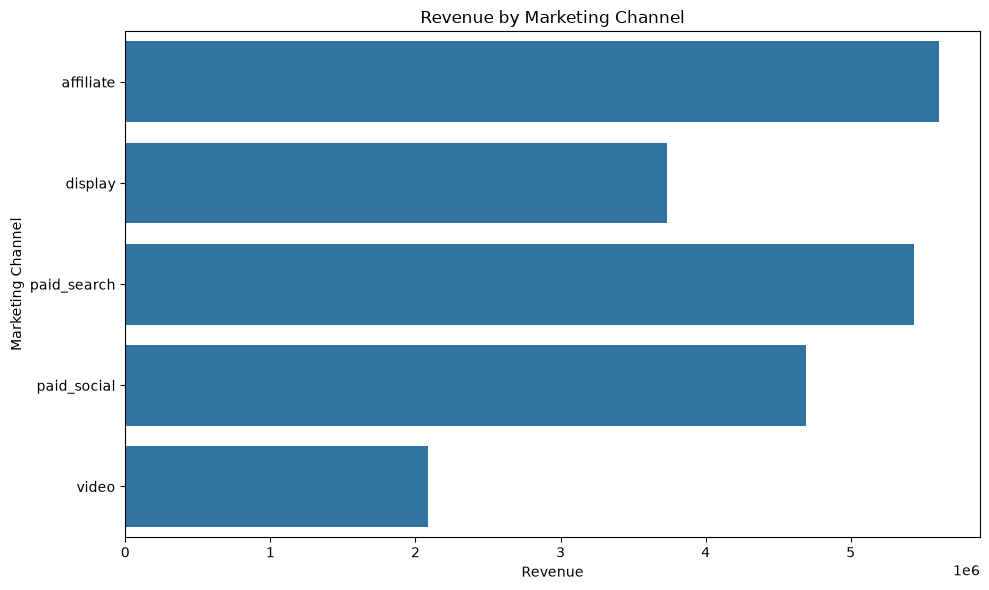

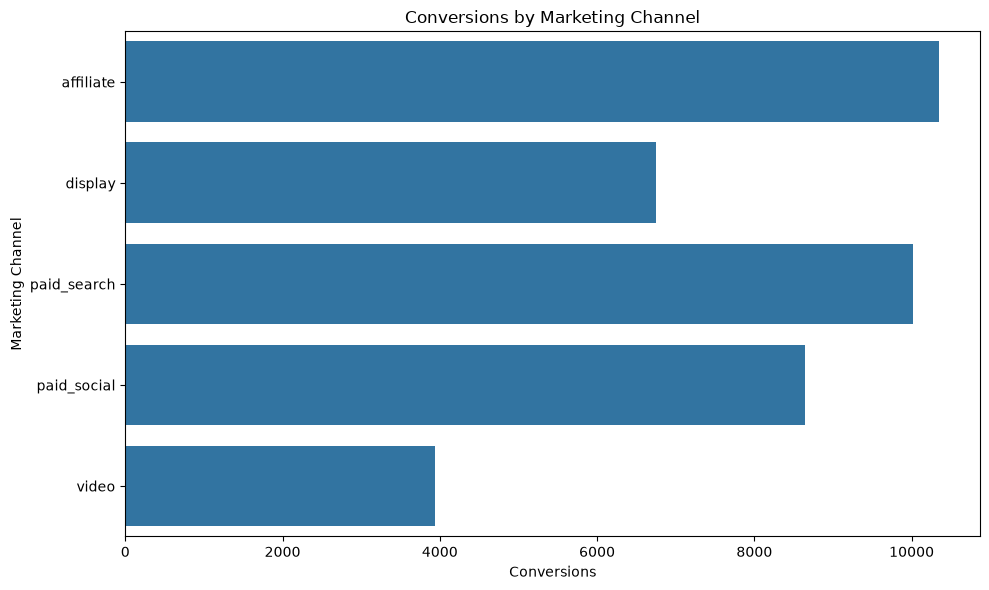

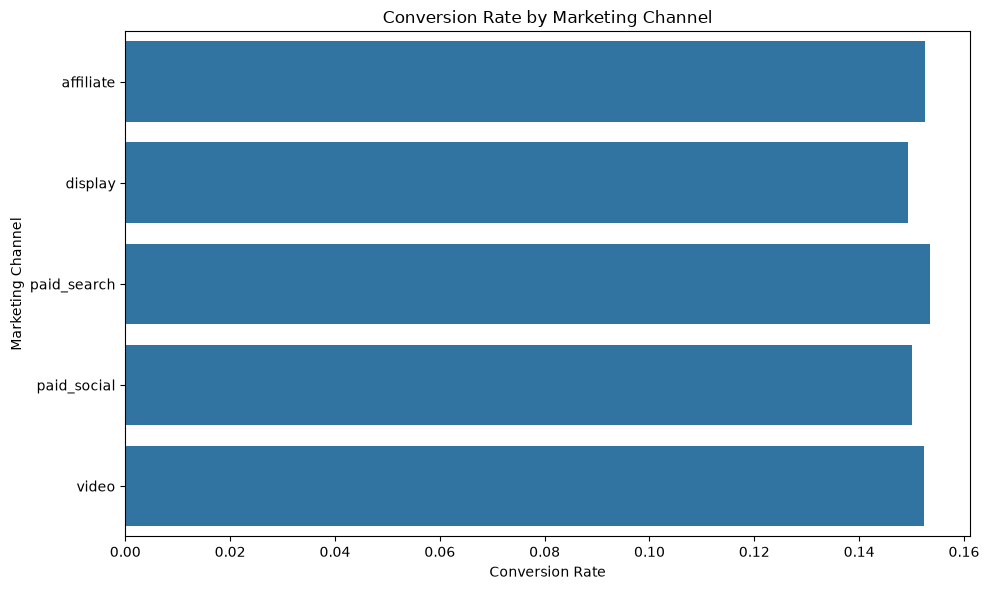

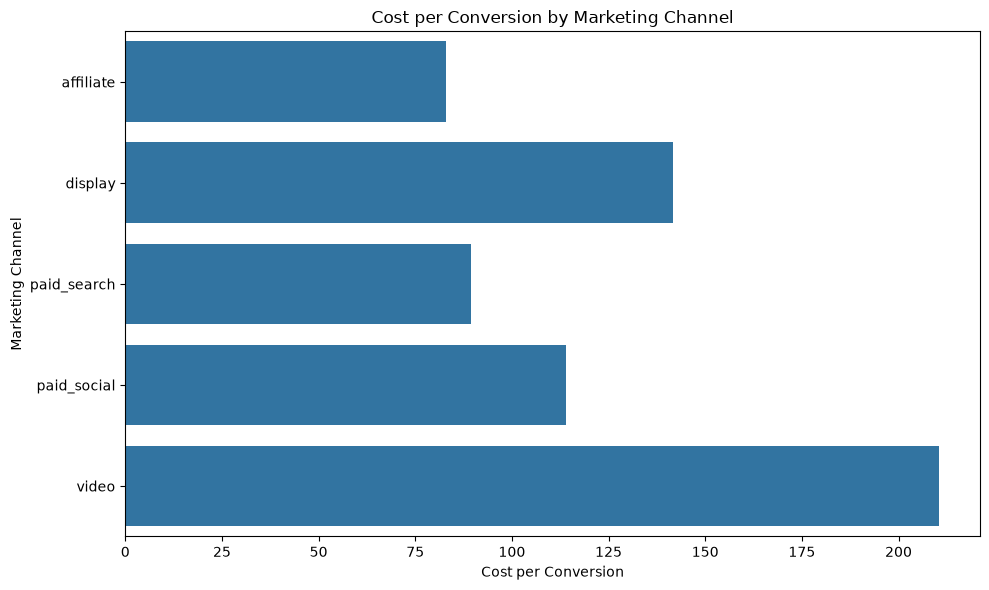

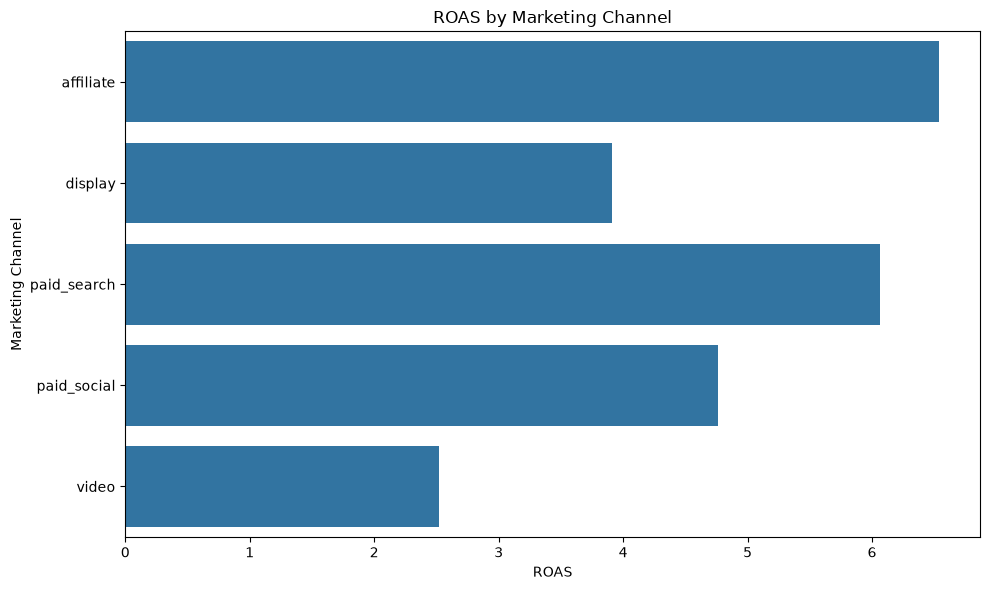

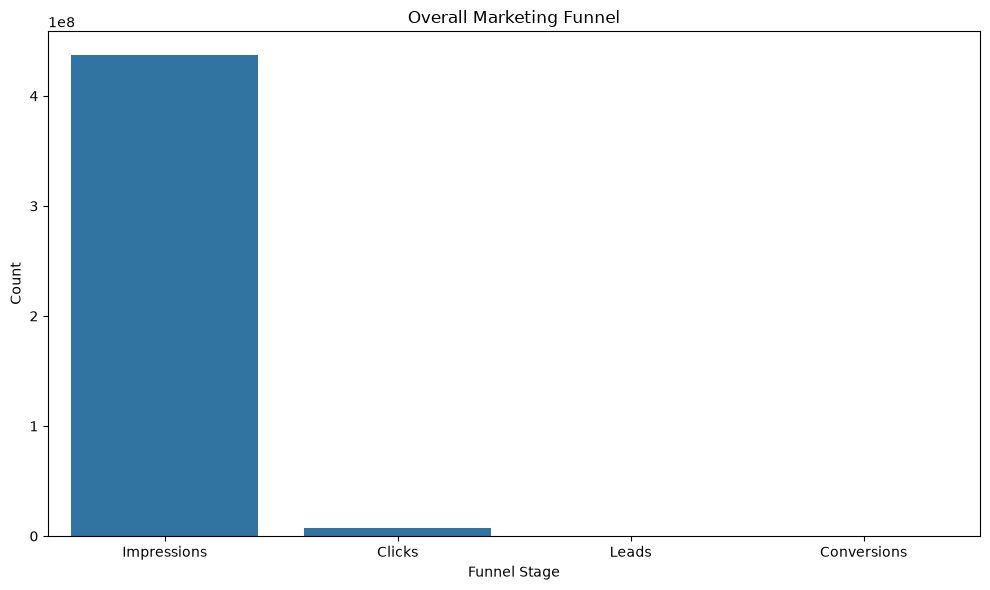

In [48]:
## Visulaization

# 1. Revenue by Marketing Channel

plt.figure(figsize=(10, 6))
sns.barplot(
    data=channel_performance,
    x="revenue",
    y="channel"
)
plt.title("Revenue by Marketing Channel")
plt.xlabel("Revenue")
plt.ylabel("Marketing Channel")
plt.tight_layout()
plt.show()


# 2. Conversions by Marketing Channel

plt.figure(figsize=(10,6))
sns.barplot(
    data=channel_performance,
    x="conversions",
     y="channel"
)
plt.title("Conversions by Marketing Channel")
plt.xlabel("Conversions")
plt.ylabel("Marketing Channel")
plt.tight_layout()
plt.show()

# 3. Conversion Rate by Marketing Channel

plt.figure(figsize=(10, 6))
sns.barplot(
    data=channel_performance,
    x="conversion_rate",
    y="channel"
)
plt.title("Conversion Rate by Marketing Channel")
plt.xlabel("Conversion Rate")
plt.ylabel("Marketing Channel")
plt.tight_layout()
plt.show()

# 4. Cost per Conversion by Marketing Channel

plt.figure(figsize=(10, 6))
sns.barplot(
    data=channel_performance,
    x="cost_per_conversion",
    y="channel"
)
plt.title("Cost per Conversion by Marketing Channel")
plt.xlabel("Cost per Conversion")
plt.ylabel("Marketing Channel")

plt.tight_layout()
plt.show()

# 5. ROAS by Marketing Channel

plt.figure(figsize=(10, 6))
sns.barplot(
    data=channel_performance,
    x="roas",
    y="channel"
)
plt.title("ROAS by Marketing Channel")
plt.xlabel("ROAS")
plt.ylabel("Marketing Channel")
plt.tight_layout()
plt.show()


# 6. Marketing Funnel

funnel = pd.DataFrame({
    "stage": [
        "Impressions",
        "Clicks",
        "Leads",
        "Conversions"
    ],
    "count": [
        df["impressions"].sum(),
        df["clicks"].sum(),
        df["leads"].sum(),
        df["conversions"].sum()
    ]
})
plt.figure(figsize=(10, 6))
sns.barplot(
    data=funnel,
    x="stage",
    y="count"
)
plt.title("Overall Marketing Funnel")
plt.xlabel("Funnel Stage")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [49]:
funnel

,stage,count
0,Impressions,436844819
1,Clicks,7102319
2,Leads,261684
3,Conversions,39696


In [50]:
## Channel Performance Summary

channel_performance.sort_values(
    "revenue",
    ascending=False
)

,channel,impressions,clicks,leads,conversions,spend,revenue,ctr,lead_conversion_rate,conversion_rate,cost_per_lead,cost_per_conversion,roas
0,affiliate,95314042,2386856,67849,10352,857835.07,5610700.73,0.025042,0.028426,0.152574,12.643297,82.866603,6.540536
2,paid_search,49837405,1740314,65268,10019,897091.53,5439329.35,0.034920,0.037504,0.153506,13.744738,89.539029,6.063294
3,paid_social,89520215,1602785,57619,8648,984731.88,4690137.28,0.017904,0.035949,0.150089,17.090402,113.868164,4.762857
1,display,146967688,879874,45149,6744,955297.00,3734117.43,0.005987,0.051313,0.149372,21.158763,141.651394,3.908855
4,video,55205469,492490,25799,3933,828094.54,2087554.22,0.008921,0.052385,0.152448,32.097932,210.550353,2.520913


In [51]:
# Channel with highest revenue
print("Highest Revenue:",channel_performance.loc[channel_performance["revenue"].idxmax(),"channel"])

# Channel with highest conversion rate
print("Highest Conversion Rate:",channel_performance.loc[channel_performance["conversion_rate"].idxmax(),"channel"])

# Channel with lowest cost per conversion
print("Lowest Cost per Conversion:",
    channel_performance.loc[channel_performance["cost_per_conversion"].idxmin(),"channel"])

# Channel with highest ROAS
print("Highest ROAS:",channel_performance.loc[channel_performance["roas"].idxmax(),"channel"])

Highest Revenue: affiliate
Highest Conversion Rate: paid_search
Lowest Cost per Conversion: affiliate
Highest ROAS: affiliate


In [53]:
# Prepare Dataset for Power BI

powerbi_data = df.copy()
powerbi_data.to_csv("marketing_campaigns_powerbi.csv",index=False)
print("Power BI dataset saved successfully.")
print("Shape:", powerbi_data.shape)

Power BI dataset saved successfully.
Shape: (11240, 9)
